# Pronóstico diario de siniestros con víctimas en Bogotá D.C. — Grupo 7
Notebook de entrega: ejecuta el pipeline completo del repositorio paso a paso. Toda la lógica vive en `src/` y los parámetros en `config/config.yaml`. Fuente: bases del Anuario de Siniestralidad Vial (SDM), 2015–2025.

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
sys.path.insert(0, os.getcwd())
import subprocess
import pandas as pd
from src.data import load_config, load_siniestros, auditoria, construir_serie, split
cfg = load_config(); cfg

# False: usa los resultados guardados en results/ (rápido). True: reentrena todo (~30 min en CPU).
REENTRENAR = False
def correr(cmd):
    if REENTRENAR:
        print(subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout[-2000:])
    else:
        print('Omitido (REENTRENAR=False):', cmd)


In [2]:
# Solo si se descargaron los .xlsx del Anuario en data/raw/anuarios_xlsx/
# !python -m scripts.extraer_anuarios

## 1. Auditoría inicial de calidad

In [3]:
raw = load_siniestros(cfg)
aud = auditoria(raw)
json.dumps(aud, ensure_ascii=False, indent=1)[:1500]

'{\n "registros": 290184,\n "fecha_min": "2015-01-01",\n "fecha_max": "2025-12-31",\n "dias_rango": 4018,\n "dias_sin_registro": 0,\n "dias_sin_victimas": 0,\n "nulos_pct": {\n  "localidad": 0.0,\n  "gravedad_tradicional": 3.99,\n  "gravedad_30d": 0.05\n },\n "gravedad": {\n  "Solo Daños": 160018,\n  "Con Heridos": 124529,\n  "Con Muertos": 5489\n },\n "clase": {\n  "Choque": 242310,\n  "Atropello": 33474,\n  "Caida de ocupante": 8193,\n  "Volcamiento": 4662,\n  "Otro": 1494,\n  "Incendio": 37,\n  "Autolesión": 14\n },\n "localidades": 20,\n "por_anio_gravedad": {\n  "2015": {\n   "Con Heridos": 10738,\n   "Con Muertos": 517,\n   "Solo Daños": 20088\n  },\n  "2016": {\n   "Con Heridos": 10581,\n   "Con Muertos": 543,\n   "Solo Daños": 23852\n  },\n  "2017": {\n   "Con Heridos": 10403,\n   "Con Muertos": 523,\n   "Solo Daños": 24217\n  },\n  "2018": {\n   "Con Heridos": 12586,\n   "Con Muertos": 485,\n   "Solo Daños": 23857\n  },\n  "2019": {\n   "Con Heridos": 12402,\n   "Con Muertos":

## 2. Serie diaria, calendario, clima y partición temporal

In [4]:
s = construir_serie(cfg, raw)
parts = split(s, cfg)
{k: (str(v.index.min().date()), str(v.index.max().date()), len(v)) for k, v in parts.items()}

{'train': ('2015-01-01', '2022-12-31', 2922),
 'val': ('2023-01-01', '2023-12-31', 365),
 'test': ('2024-01-01', '2025-12-31', 731)}

In [5]:
s[['y','lluvia_mm','festivo','confinamiento']].describe()

,y,lluvia_mm,festivo,confinamiento
count,4018.000000,4018.000000,4018.000000,4018.000000
mean,32.358885,2.457516,0.048780,0.132902
std,8.865724,3.629717,0.215436,0.339511
min,2.000000,0.000000,0.000000,0.000000
25%,26.000000,0.400000,0.000000,0.000000
50%,33.000000,1.200000,0.000000,0.000000
75%,38.000000,3.100000,0.000000,0.000000
max,61.000000,55.200000,1.000000,1.000000


## 3. Líneas base (E0)

In [6]:
correr('python -m scripts.run_baselines')
correr('python -m scripts.run_baselines indicador')
b = json.load(open('results/baselines_metricas.json'))
pd.DataFrame({k: {'val_MAE': v['val']['MAE'], 'test_MAE': v['test']['MAE']} for k, v in b.items() if not k.startswith('_')}).T.round(2)

Omitido (REENTRENAR=False): python -m scripts.run_baselines
Omitido (REENTRENAR=False): python -m scripts.run_baselines indicador


,val_MAE,test_MAE
Naive estacional (t-7),7.41,7.75
Media estacional (4 sem.),5.97,6.27
Ridge con rezagos,5.23,5.47
SARIMAX,5.29,5.46


## 4. Redes recurrentes: rejilla, 3 semillas y ablaciones, incluida la pandemia (E1–E6, ~30 min en CPU)

In [7]:
correr('python -m scripts.run_experiments')

Omitido (REENTRENAR=False): python -m scripts.run_experiments


In [8]:
pd.read_csv('results/grid_search.csv').sort_values('val_MAE').head(10)

,modelo,ventana,hidden,lr,dropout,val_MAE,val_RMSE,epocas,seg,params
9,GRU,28,32,0.001,0.2,4.954274,6.426792,100,27.278407,7719
24,LSTM,28,32,0.001,0.0,4.960014,6.394495,39,5.244359,8967
31,LSTM,28,64,0.003,0.2,4.961211,6.409448,39,8.009283,28167
26,LSTM,28,32,0.003,0.0,4.971793,6.411873,34,4.558476,8967
27,LSTM,28,32,0.003,0.2,4.980862,6.464231,36,4.636222,8967
11,GRU,28,32,0.003,0.2,4.984444,6.453311,39,10.294734,7719
16,LSTM,14,32,0.001,0.0,4.987290,6.416066,75,8.321663,8967
20,LSTM,14,64,0.001,0.0,4.996870,6.440842,43,5.826333,28167
30,LSTM,28,64,0.003,0.0,5.007512,6.443355,34,6.650676,28167
8,GRU,28,32,0.001,0.0,5.007547,6.453029,53,13.880268,7719


## 5. Comparación final en prueba, Diebold–Mariano y análisis de errores (E6–E7)

In [9]:
correr('python -m scripts.run_evaluacion')

Omitido (REENTRENAR=False): python -m scripts.run_evaluacion


In [10]:
pd.read_csv('results/comparacion_final.csv').round(2)

,modelo,tipo,val_MAE,test_MAE,test_MAE_sd,test_RMSE,test_MAPE,test_RMSLE,seg_entreno,seg_pred_test,parametros
0,Naive estacional (t-7),Línea base,7.41,7.75,0.00,9.67,25.38,0.31,0.00,0.00,NaN
1,Media estacional (4 sem.),Línea base,5.97,6.27,0.00,7.88,20.85,0.24,0.00,0.04,NaN
2,Ridge con rezagos,Línea base,5.23,5.47,0.00,6.80,17.56,0.21,5.53,1.69,NaN
3,SARIMAX,Línea base,5.29,5.46,0.00,6.81,17.56,0.21,9.74,22.47,NaN
4,GRU,Avanzado,4.96,5.35,0.05,6.64,17.55,0.21,24.28,0.24,7719.0
5,GRU sin lluvia,Ablación,4.99,5.24,0.01,6.54,16.93,0.20,15.34,0.01,7623.0
6,GRU sin calendario futuro,Ablación,5.51,5.76,0.02,7.24,19.28,0.23,19.81,0.01,7719.0
7,GRU con pandemia + indicador,Ablación,5.05,5.31,0.01,6.59,17.22,0.20,18.31,0.01,8039.0
8,LSTM,Avanzado,4.98,5.35,0.03,6.64,17.46,0.20,5.66,0.00,8967.0
9,LSTM sin lluvia,Ablación,4.97,5.30,0.02,6.59,17.21,0.20,6.81,0.00,8839.0


In [11]:
pd.read_csv('results/diebold_mariano.csv').round(4)

,modelo,vs,MAE_modelo,MAE_base,mejora_pct,DM_h1a7,p_h1a7,DM_h1,p_h1
0,GRU,SARIMAX,5.3904,5.4622,1.3141,0.6334,0.5267,0.7693,0.4420
1,GRU,Ridge con rezagos,5.3904,5.4721,1.4933,0.8596,0.3903,0.2156,0.8293
2,LSTM,SARIMAX,5.3252,5.4622,2.5081,1.3103,0.1905,1.4239,0.1549
3,LSTM,Ridge con rezagos,5.3252,5.4721,2.6851,2.0625,0.0395,1.1577,0.2474


## 6. Figuras

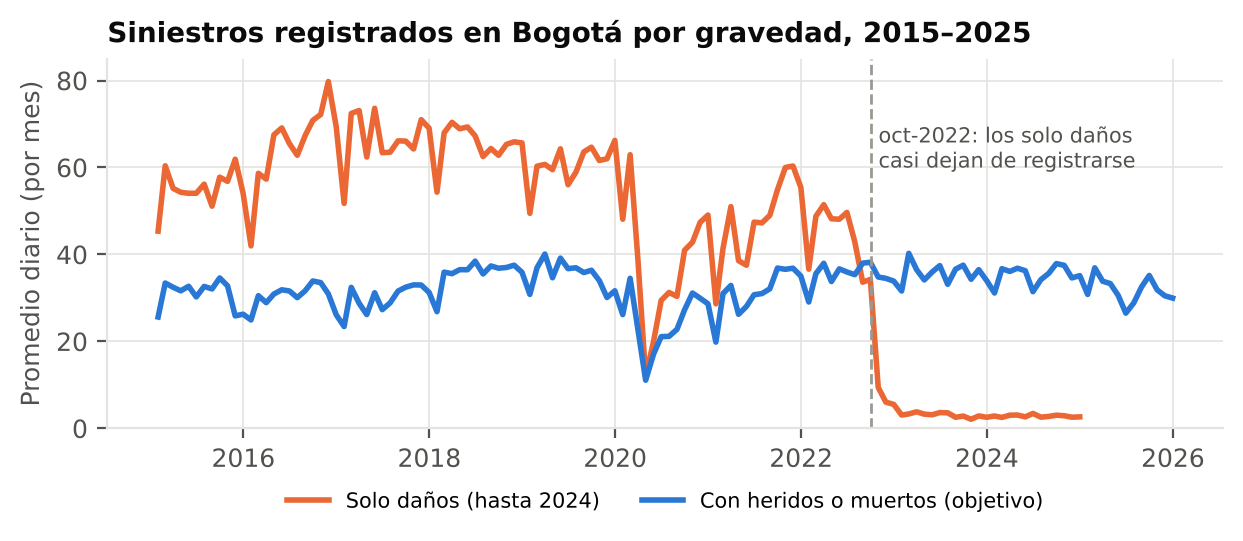

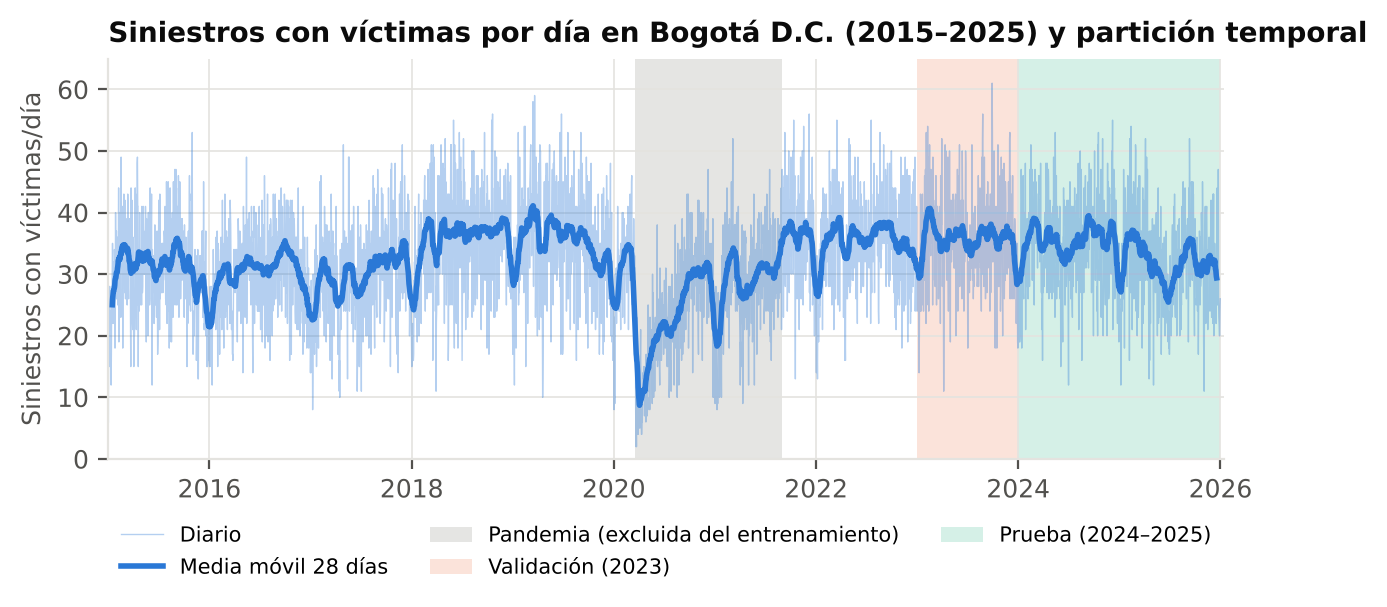

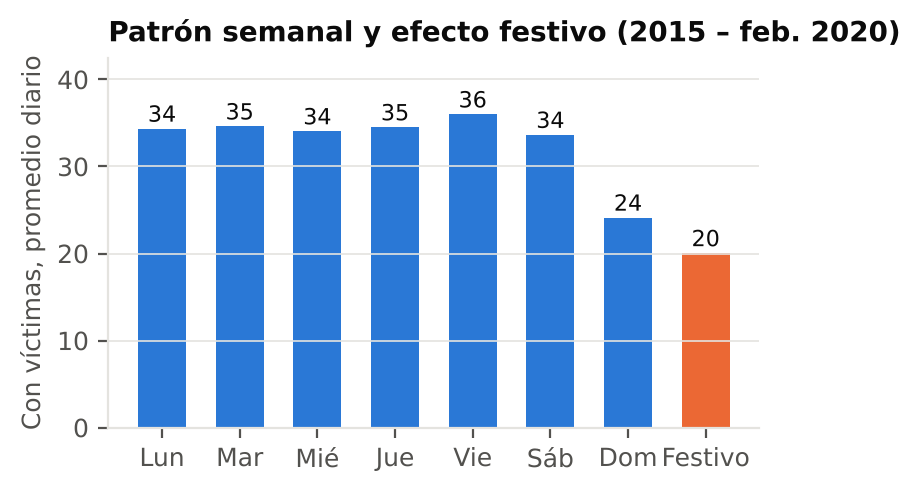

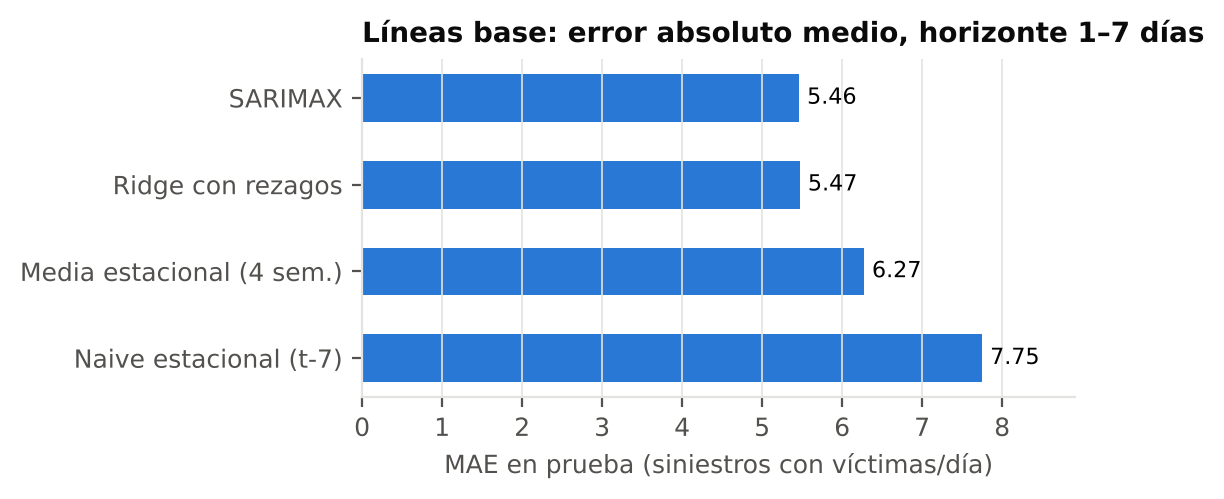

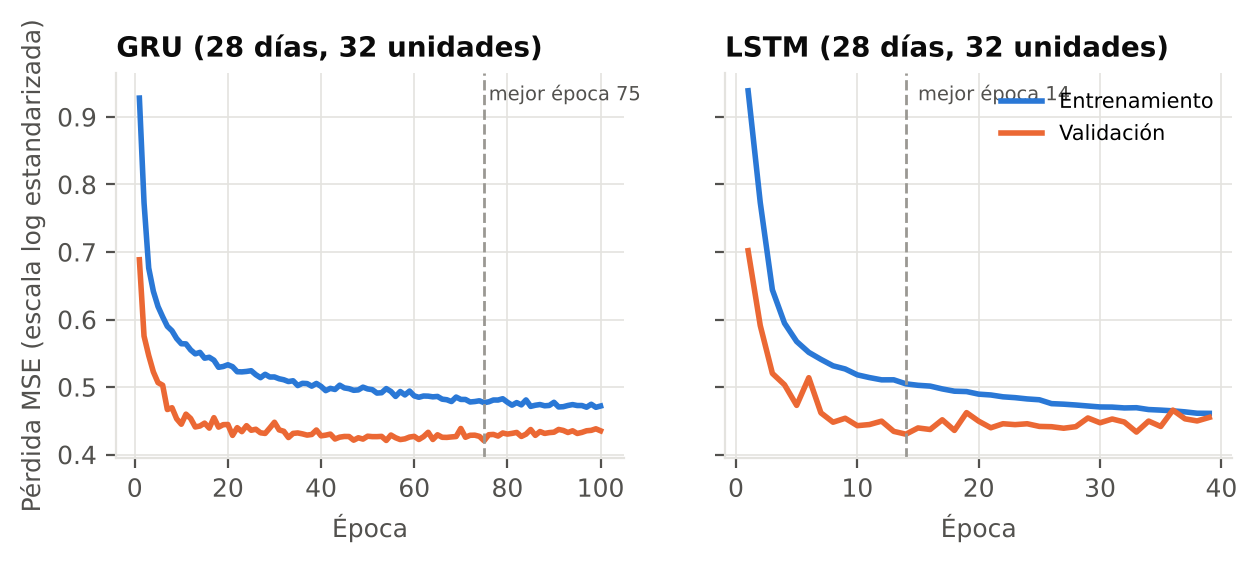

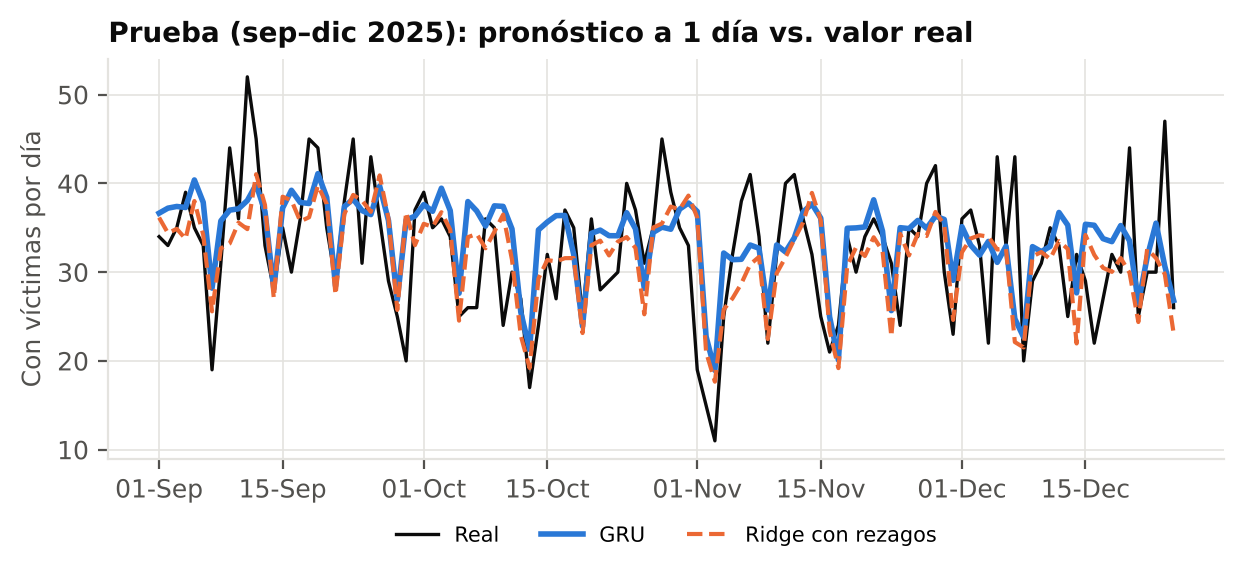

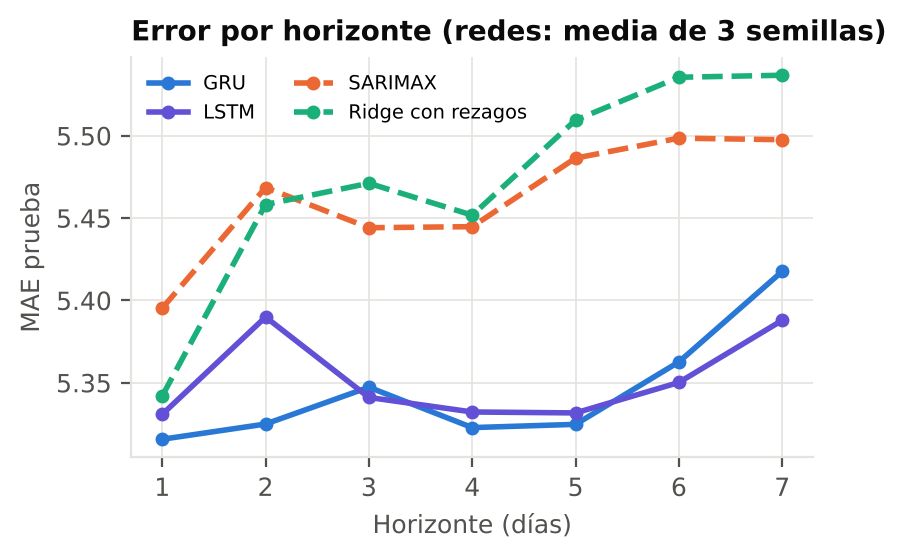

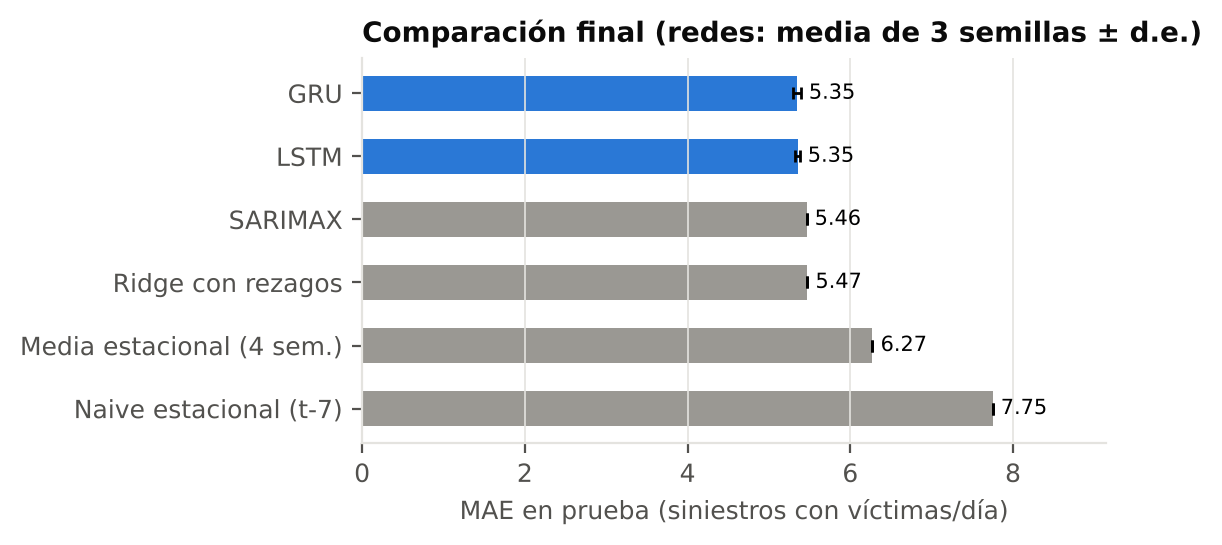

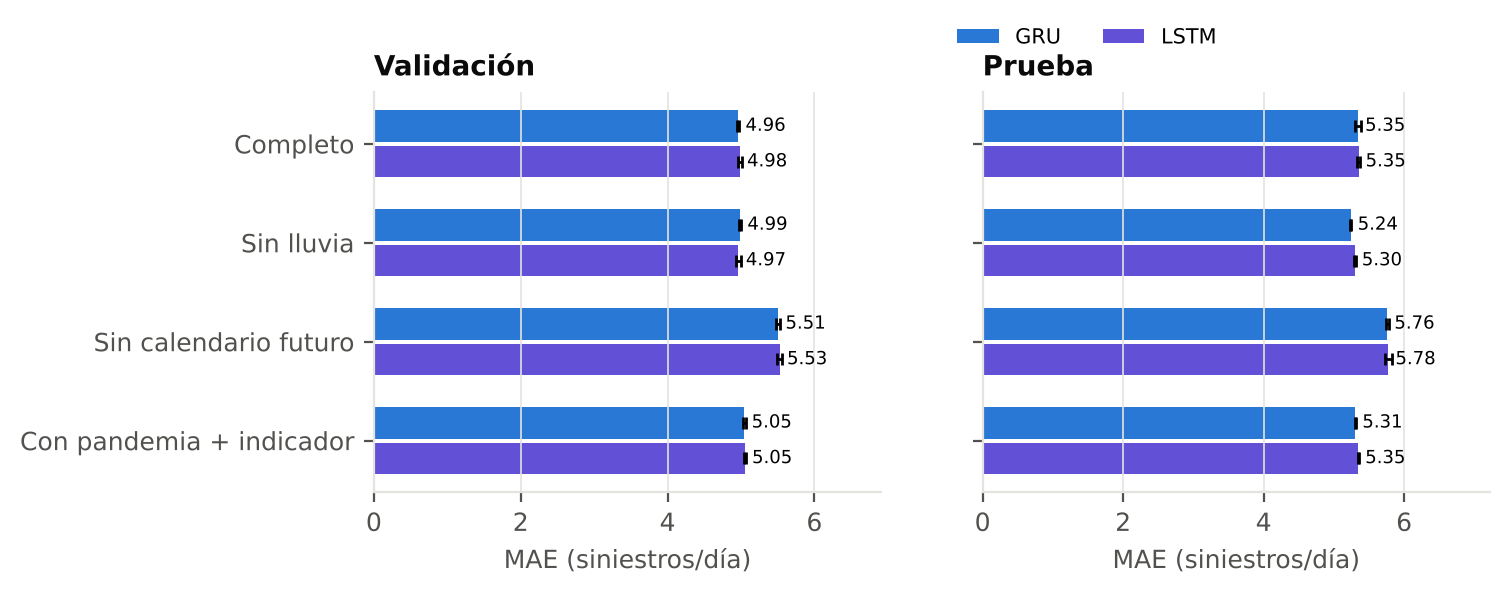

In [12]:
from IPython.display import Image, display
for f in sorted(os.listdir('figures')):
    display(Image(filename=os.path.join('figures', f), width=700))